# Evaluasi test Panoptic Indoor v5 dengan empat model

Notebook ini mengunduh **Panoptic Indoor Segmentation v5** melalui Roboflow API, lalu mengevaluasi split `test` dengan empat checkpoint dari Kaggle Input:

- YOLO11n-seg dengan pretrained weights
- YOLO11n-seg tanpa pretrained weights
- YOLO11s-seg
- Mask R-CNN ResNet-50 FPN

Notebook hanya melakukan inferensi dan evaluasi. Ia tidak melatih ulang model. Mask R-CNN memakai urutan kelas kategori COCO pada split `train` versi 5, sama seperti notebook training; prediksi kemudian dicocokkan ke kategori test berdasarkan nama kelas.

## Persiapan Kaggle

1. Di **Add Input**, tambahkan dataset bobot yang berisi `yolo11n_best.pt`, `yolo11n_no_pretrained_best.pt`, `yolo11s_best.pt`, dan `maskrcnn_best.pth`. Notebook mencari nama file tersebut di seluruh `/kaggle/input`.
2. Di **Add-ons → Secrets**, tambahkan `ROBOFLOW_API_KEY` dengan API key Roboflow-mu. Jangan tulis API key langsung di notebook.
3. Aktifkan GPU, lalu jalankan semua cell dari atas ke bawah.

Hasil utama disimpan di `/kaggle/working/panoptic_test_evaluation/` dan dikemas menjadi `/kaggle/working/panoptic_test_evaluation.zip`. Untuk membandingkannya dengan 40 foto pribadi, gunakan `mask_mAP50` dan `mask_mAP50_95` dari file `panoptic_test_metrics.csv`.


## 1. Instalasi pustaka

In [1]:
!pip install -q roboflow ultralytics pycocotools

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Unduh dataset Panoptic Indoor v5 lewat API

In [3]:
from pathlib import Path
import json, re, time, csv, shutil, zipfile
from collections import defaultdict
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from roboflow import Roboflow
from kaggle_secrets import UserSecretsClient
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils
from torchvision.models.detection import maskrcnn_resnet50_fpn

INPUT_ROOT = Path('/kaggle/input')
WORK_ROOT = Path('/kaggle/working')
OUT_DIR = WORK_ROOT / 'panoptic_test_evaluation'
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), 'Aktifkan GPU di Notebook Settings.'
DEVICE = 'cuda:0'
print('GPU:', torch.cuda.get_device_name(0))

def find_unique(filename):
    matches = list(INPUT_ROOT.rglob(filename))
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Diharapkan satu file {filename} di Kaggle Input; ditemukan {len(matches)}. '
            'Periksa Add Input dan nama file.'
        )
    return matches[0]

MODEL_PATHS = {
    'YOLO11n-seg pretrained': find_unique('yolo11n_best.pt'),
    'YOLO11n-seg tanpa pretrained': find_unique('yolo11n_no_pretrained_best.pt'),
    'YOLO11s-seg': find_unique('yolo11s_best.pt'),
    'Mask R-CNN ResNet-50 FPN': find_unique('maskrcnn_best.pth'),
}
for name, path in MODEL_PATHS.items(): print(name, '->', path)

api_key = UserSecretsClient().get_secret('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=api_key)
project = rf.workspace('panopticindoor').project('panoptic-indoor-segmentation')
version = project.version(5)
dataset = version.download('coco-segmentation')
DATA_ROOT = Path(dataset.location)
print('Panoptic Indoor v5:', DATA_ROOT)


GPU: Tesla T4
YOLO11n-seg pretrained -> /kaggle/input/models/akmalfayyazi/panoptic-finetuned/pytorch/default/3/yolo11n_best.pt
YOLO11n-seg tanpa pretrained -> /kaggle/input/models/akmalfayyazi/panoptic-finetuned/pytorch/default/3/yolo11n_no_pretrained_best.pt
YOLO11s-seg -> /kaggle/input/models/akmalfayyazi/panoptic-finetuned/pytorch/default/3/yolo11s_best.pt
Mask R-CNN ResNet-50 FPN -> /kaggle/input/models/akmalfayyazi/panoptic-finetuned/pytorch/default/3/maskrcnn_best.pth
loading Roboflow workspace...
loading Roboflow project...


Extracting Dataset Version Zip to panoptic-indoor-segmentation-5 in coco-segmentation:: 100%|██████████| 930/930 [00:00<00:00, 7129.90it/s]

Panoptic Indoor v5: /kaggle/working/panoptic-indoor-segmentation-5


## 3. Temukan anotasi COCO untuk split train dan test

In [4]:
def find_coco_json_for_split(root, split):
    aliases = {'train': {'train'}, 'test': {'test'}}[split]
    matches = []
    for jf in root.rglob('*.json'):
        try:
            obj = json.loads(jf.read_text())
        except Exception:
            continue
        if not isinstance(obj, dict) or not {'images','annotations','categories'} <= set(obj):
            continue
        rel_parts = {part.lower() for part in jf.relative_to(root).parts[:-1]}
        if rel_parts & aliases:
            matches.append((jf, obj))
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Perlu tepat satu anotasi COCO untuk split {split}; ditemukan {len(matches)}. '
            f'Periksa struktur dataset hasil API di {root}.'
        )
    return matches[0]

train_json, train_obj = find_coco_json_for_split(DATA_ROOT, 'train')
test_json, test_obj = find_coco_json_for_split(DATA_ROOT, 'test')
train_categories = sorted(train_obj['categories'], key=lambda c: int(c['id']))
test_categories = sorted(test_obj['categories'], key=lambda c: int(c['id']))
print('Train annotation:', train_json, '| classes:', len(train_categories))
print('Test annotation:', test_json, '| images:', len(test_obj['images']), '| classes:', len(test_categories))

class_key = lambda x: re.sub(r'[^a-z0-9]+', '', str(x).lower())
test_cat_by_key = {class_key(c['name']): int(c['id']) for c in test_categories}
train_class_names = [str(c['name']) for c in train_categories]


Train annotation: /kaggle/working/panoptic-indoor-segmentation-5/train/_annotations.coco.json | classes: 75
Test annotation: /kaggle/working/panoptic-indoor-segmentation-5/test/_annotations.coco.json | images: 359 | classes: 75


## 4. Siapkan kategori dan lokasi gambar test

In [5]:
gt = COCO(str(test_json))
cat_ids = sorted(gt.getCatIds())
image_info = {int(im['id']): im for im in gt.loadImgs(gt.getImgIds())}
TEST_DIR = test_json.parent

def resolve_image(file_name):
    rel = Path(file_name)
    candidates = [TEST_DIR / rel, TEST_DIR / rel.name, DATA_ROOT / rel, DATA_ROOT / rel.name]
    for path in candidates:
        if path.exists(): return path.resolve()
    hits = list(DATA_ROOT.rglob(rel.name))
    if hits: return hits[0].resolve()
    raise FileNotFoundError(f'Gambar test tidak ditemukan: {file_name}')

image_paths = {image_id: resolve_image(info['file_name']) for image_id, info in image_info.items()}
print('Jumlah gambar test:', len(image_paths))
print('Contoh kelas:', [c['name'] for c in gt.loadCats(cat_ids)[:15]])


loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Jumlah gambar test: 359
Contoh kelas: ['indoor-objects', 'backpack', 'bed', 'blanket', 'book', 'bottle', 'bowl', 'box', 'cabinet-merged', 'cardboard', 'ceiling-merged', 'cell phone', 'chair', 'clock', 'couch']


## 5. Muat empat model dan cocokkan kelas berdasarkan nama

In [9]:
def unwrap_state_dict(obj):
    if isinstance(obj, dict):
        for key in ("model_state_dict", "state_dict", "model"):
            if key in obj and isinstance(obj[key], dict):
                obj = obj[key]
                break

    if not isinstance(obj, dict):
        raise TypeError("Checkpoint Mask R-CNN bukan state_dict yang dikenali.")

    return {
        key.removeprefix("module."): value
        for key, value in obj.items()
        if torch.is_tensor(value)
    }


def load_maskrcnn(path):
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    state = unwrap_state_dict(checkpoint)

    cls_key = "roi_heads.box_predictor.cls_score.weight"
    if cls_key not in state:
        raise KeyError(f"Checkpoint tidak memiliki {cls_key}.")

    n_classes = int(state[cls_key].shape[0])

    model = maskrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None,
        num_classes=n_classes,
    )
    model.load_state_dict(state, strict=True)
    model.transform.min_size = (640,)
    model.transform.max_size = 640
    model.roi_heads.score_thresh = 0.001
    model.roi_heads.detections_per_img = 100

    return model.to(DEVICE).eval()


models = {}
yolo_class_maps = {}

for model_name in (
    "YOLO11n-seg pretrained",
    "YOLO11n-seg tanpa pretrained",
    "YOLO11s-seg",
):
    model = YOLO(str(MODEL_PATHS[model_name]))
    names = model.names

    if isinstance(names, dict):
        names = [names[k] for k in sorted(names, key=lambda x: int(x))]

    mapping = {}
    ignored = []

    for idx, name in enumerate(names):
        key = class_key(name)
        if key in test_cat_by_key:
            mapping[idx] = test_cat_by_key[key]
        else:
            ignored.append(name)

    if not mapping:
        raise ValueError(f"Tidak ada kelas {model_name} yang cocok dengan COCO test.")

    yolo_class_maps[model_name] = mapping
    models[model_name] = model
    print(model_name, "kelas cocok:", len(mapping), "/", len(names), "| diabaikan:", ignored)


# Mask R-CNN dilatih dengan urutan kelas yang sama seperti YOLO11n.
yolo_names = models["YOLO11n-seg pretrained"].names
if isinstance(yolo_names, dict):
    yolo_names = [
        yolo_names[k] for k in sorted(yolo_names, key=lambda x: int(x))
    ]

maskrcnn_model = load_maskrcnn(
    MODEL_PATHS["Mask R-CNN ResNet-50 FPN"]
)

maskrcnn_class_map = {}
maskrcnn_ignored = []

for label, name in enumerate(yolo_names, start=1):
    key = class_key(name)
    if key in test_cat_by_key:
        maskrcnn_class_map[label] = test_cat_by_key[key]
    else:
        maskrcnn_ignored.append(name)

if not maskrcnn_class_map:
    raise ValueError("Tidak ada kelas Mask R-CNN yang cocok dengan COCO test.")

models["Mask R-CNN ResNet-50 FPN"] = maskrcnn_model

print(
    "Mask R-CNN kelas cocok:",
    len(maskrcnn_class_map),
    "/",
    len(yolo_names),
    "| diabaikan:",
    maskrcnn_ignored,
)

YOLO11n-seg pretrained kelas cocok: 74 / 74 | diabaikan: []
YOLO11n-seg tanpa pretrained kelas cocok: 74 / 74 | diabaikan: []
YOLO11s-seg kelas cocok: 74 / 74 | diabaikan: []
Mask R-CNN kelas cocok: 74 / 74 | diabaikan: []


## 6. Jalankan inferensi pada split test Panoptic

In [10]:
def encode_mask(binary):
    rle = mask_utils.encode(np.asfortranarray(binary.astype(np.uint8)))
    rle['counts'] = rle['counts'].decode('utf-8')
    return rle

def fit_mask(mask, height, width):
    if mask.shape == (height, width): return mask.astype(np.uint8)
    return np.asarray(Image.fromarray(mask.astype(np.uint8)).resize((width, height), Image.Resampling.NEAREST), dtype=np.uint8)

def mask_box_area(mask):
    ys, xs = np.where(mask > 0)
    if not len(xs): return [0, 0, 0, 0], 0
    return [int(xs.min()), int(ys.min()), int(xs.max()-xs.min()+1), int(ys.max()-ys.min()+1)], int(mask.sum())

all_predictions = {}
runtime_rows = []
for model_name, model in models.items():
    print('Evaluasi split test:', model_name)
    predictions = []
    durations = []
    for image_id, image_path in image_paths.items():
        image = Image.open(image_path).convert('RGB')
        width, height = image.size
        start = time.perf_counter()
        if model_name.startswith('YOLO'):
            result = model.predict(source=np.asarray(image), imgsz=640, conf=0.001, iou=0.7, max_det=100, device=0, verbose=False)[0]
            if result.masks is not None:
                masks = result.masks.data.detach().cpu().numpy()
                labels = result.boxes.cls.detach().cpu().numpy().astype(int)
                scores = result.boxes.conf.detach().cpu().numpy()
                for raw, label, score in zip(masks, labels, scores):
                    label = int(label)
                    if label not in yolo_class_maps[model_name]: continue
                    binary = fit_mask(raw > 0.5, height, width)
                    if not binary.any(): continue
                    bbox, area = mask_box_area(binary)
                    predictions.append({'image_id': image_id, 'category_id': yolo_class_maps[model_name][label], 'segmentation': encode_mask(binary), 'bbox': bbox, 'area': area, 'score': float(score)})
        else:
            tensor = torch.from_numpy(np.asarray(image).copy()).permute(2,0,1).float().div(255).to(DEVICE)
            with torch.inference_mode(): pred = model([tensor])[0]
            masks = pred['masks'][:,0].detach().cpu().numpy()
            labels = pred['labels'].detach().cpu().numpy().astype(int)
            scores = pred['scores'].detach().cpu().numpy()
            for raw, label, score in zip(masks, labels, scores):
                label = int(label)
                if label not in maskrcnn_class_map: continue
                binary = fit_mask(raw >= 0.5, height, width)
                if not binary.any(): continue
                bbox, area = mask_box_area(binary)
                predictions.append({'image_id': image_id, 'category_id': maskrcnn_class_map[label], 'segmentation': encode_mask(binary), 'bbox': bbox, 'area': area, 'score': float(score)})
        durations.append(time.perf_counter() - start)
    all_predictions[model_name] = predictions
    runtime_rows.append({'model': model_name, 'test_images': len(image_paths), 'predicted_instances': len(predictions), 'mean_inference_seconds_per_image': float(np.mean(durations)), 'total_inference_seconds': float(np.sum(durations))})
    slug = re.sub(r'[^a-z0-9]+', '_', model_name.lower()).strip('_')
    (OUT_DIR / f'{slug}_predictions.json').write_text(json.dumps(predictions))
print('Inferensi pada split test selesai.')


Evaluasi split test: YOLO11n-seg pretrained
Evaluasi split test: YOLO11n-seg tanpa pretrained
Evaluasi split test: YOLO11s-seg
Evaluasi split test: Mask R-CNN ResNet-50 FPN
Inferensi pada split test selesai.


## 7. Hitung mask mAP dan AP tiap kelas

In [11]:
summary_rows = []
per_class_rows = []
for model_name, predictions in all_predictions.items():
    if predictions:
        dt = gt.loadRes(predictions)
        evaluator = COCOeval(gt, dt, iouType='segm')
        evaluator.params.imgIds = sorted(image_paths)
        evaluator.params.catIds = cat_ids
        evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
        stats = evaluator.stats
        precision = evaluator.eval['precision']
        for pos, cat_id in enumerate(evaluator.params.catIds):
            values = precision[:,:,pos,0,-1]
            values = values[values > -1]
            per_class_rows.append({'model': model_name, 'class_name': gt.loadCats([cat_id])[0]['name'], 'mask_AP50_95': float(values.mean()) if values.size else np.nan})
        row = {'model': model_name, 'test_images': len(image_paths), 'predicted_instances': len(predictions), 'mask_mAP50_95': float(stats[0]), 'mask_mAP50': float(stats[1]), 'mask_mAP75': float(stats[2]), 'mask_AP_small': float(stats[3]), 'mask_AP_medium': float(stats[4]), 'mask_AP_large': float(stats[5])}
    else:
        row = {'model': model_name, 'test_images': len(image_paths), 'predicted_instances': 0, 'mask_mAP50_95': 0.0, 'mask_mAP50': 0.0, 'mask_mAP75': 0.0, 'mask_AP_small': 0.0, 'mask_AP_medium': 0.0, 'mask_AP_large': 0.0}
        for cat_id in cat_ids: per_class_rows.append({'model': model_name, 'class_name': gt.loadCats([cat_id])[0]['name'], 'mask_AP50_95': np.nan})
    runtime = next(r for r in runtime_rows if r['model'] == model_name)
    row['mean_inference_seconds_per_image'] = runtime['mean_inference_seconds_per_image']
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
per_class = pd.DataFrame(per_class_rows)
summary.to_csv(OUT_DIR / 'panoptic_test_metrics.csv', index=False)
per_class.to_csv(OUT_DIR / 'panoptic_test_per_class_ap.csv', index=False)
pd.DataFrame(runtime_rows).to_csv(OUT_DIR / 'panoptic_test_inference_time.csv', index=False)
print(summary.to_string(index=False))


Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=3.63s).
Accumulating evaluation results...
DONE (t=0.86s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.058
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.111
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.051
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.022
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.062
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.082
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.086
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.142
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.150
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

## 8. Buat grafik dan paket hasil unduhan

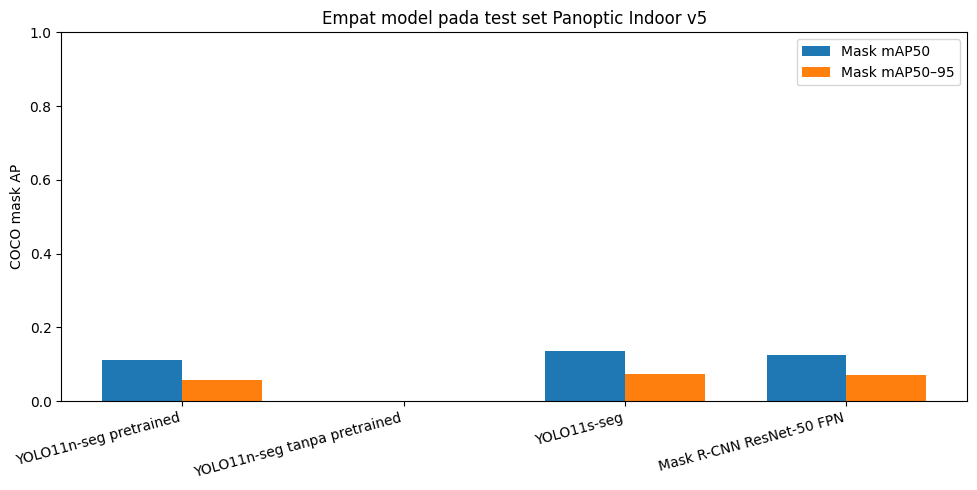

ZIP hasil siap diunduh: /kaggle/working/panoptic_test_evaluation.zip
Folder output: /kaggle/working/panoptic_test_evaluation


In [12]:
fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(summary)); w = 0.36
ax.bar(x-w/2, summary['mask_mAP50'], w, label='Mask mAP50')
ax.bar(x+w/2, summary['mask_mAP50_95'], w, label='Mask mAP50–95')
ax.set_xticks(x, summary['model'], rotation=15, ha='right')
ax.set_ylim(0,1); ax.set_ylabel('COCO mask AP')
ax.set_title('Empat model pada test set Panoptic Indoor v5')
ax.legend(); fig.tight_layout()
fig.savefig(OUT_DIR / 'panoptic_test_model_comparison.png', dpi=180); plt.show()

run_info = {
    'dataset': 'Panoptic Indoor Segmentation v5',
    'roboflow_format': 'coco-segmentation',
    'evaluated_split': 'test',
    'test_images': len(image_paths),
    'test_classes': [c['name'] for c in gt.loadCats(cat_ids)],
    'maskrcnn_class_order_source': str(train_json),
    'models': {name: str(path) for name,path in MODEL_PATHS.items()},
    'gpu': torch.cuda.get_device_name(0),
    'imgsz': 640,
    'confidence_threshold': 0.001,
    'max_detections_per_image': 100,
}
(OUT_DIR / 'run_info.json').write_text(json.dumps(run_info, indent=2))
readme = '\n'.join([
    'PANOPTIC INDOOR V5 TEST EVALUATION',
    '',
    'panoptic_test_metrics.csv: COCO mask mAP50, mAP50-95, mAP75, AP sizes for the test split.',
    'panoptic_test_per_class_ap.csv: per-class mask AP.',
    'panoptic_test_inference_time.csv: inference runtime per model.',
    'panoptic_test_model_comparison.png: metric comparison chart.',
    '*_predictions.json: COCO-format mask predictions.',
    'run_info.json: data split and inference configuration.',
])
(OUT_DIR / 'README_OUTPUT.txt').write_text(readme)
ZIP_PATH = WORK_ROOT / 'panoptic_test_evaluation.zip'
if ZIP_PATH.exists(): ZIP_PATH.unlink()
shutil.make_archive(str(ZIP_PATH.with_suffix('')), 'zip', root_dir=OUT_DIR)
print('ZIP hasil siap diunduh:', ZIP_PATH)
print('Folder output:', OUT_DIR)


## File hasil

Unduh `panoptic_test_evaluation.zip` dari panel **Output** Kaggle. File utama untuk mengisi tabel domain shift adalah `panoptic_test_metrics.csv`. Cocokkan baris tiap model dengan hasil test foto pribadi. `panoptic_test_per_class_ap.csv`, grafik, waktu inferensi, dan prediksi COCO menjadi bukti tambahan.
